# 全8クラスタの年別推移

クラスタ0・4除外後の36,142発言について、残る8クラスタの年別件数と年内構成比を比較します。KMeansの再学習や発言の再割当は行いません。2026年は取得途中のデータです。

In [1]:
from pathlib import Path
import os

ROOT = Path.cwd()
if not (ROOT / 'analysis').exists():
    ROOT = ROOT.parent
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.matplotlib'))
Path(os.environ['MPLCONFIGDIR']).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.ticker import PercentFormatter
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

INPUT_PATH = ROOT / 'analysis/clustering_2016_2026_nouns_excluding_0_4_renormalized/speech_clusters_excluding_0_4.csv'
OUTPUT_DIR = ROOT / 'analysis/all_clusters_yearly'
EXPECTED_ROWS = 36142
YEARS = list(range(2016, 2027))
CLUSTERS = [1, 2, 3, 5, 6, 7, 8, 9]
CLUSTER_LABELS = {
    1: '感染症・公衆衛生',
    2: '政治・政党・政治資金',
    3: '経済・物価・賃金',
    5: '予算・財政運営',
    6: '調査・報告・検証',
    7: '社会保障・子育て支援',
    8: '防衛・安全保障',
    9: '外交・国際関係',
}
COLORS = dict(zip(CLUSTERS, sns.color_palette('tab10', n_colors=len(CLUSTERS))))
MARKERS = dict(zip(CLUSTERS, ['o', 's', '^', 'D', 'P', 'X', 'v', '*']))

sns.set_theme(style='whitegrid')
mac_font_paths = list(Path('/System/Library/Fonts').glob('*角*W3.ttc'))
if not mac_font_paths:
    raise FileNotFoundError('macOSのヒラギノ角ゴシック W3が見つかりません')
font_manager.fontManager.addfont(str(mac_font_paths[0]))
MAC_JAPANESE_FONT = font_manager.FontProperties(fname=str(mac_font_paths[0])).get_name()
plt.rcParams['font.family'] = MAC_JAPANESE_FONT
plt.rcParams['axes.unicode_minus'] = False
print(f'Matplotlib font: {MAC_JAPANESE_FONT}')

Matplotlib font: Hiragino Sans


## 1. 入力データの検証

In [2]:
df = pd.read_csv(INPUT_PATH, encoding='utf-8-sig', usecols=['speechID', 'year', 'cluster', 'cluster_label'])
assert len(df) == EXPECTED_ROWS
assert df['speechID'].is_unique
assert sorted(df['year'].unique()) == YEARS
assert sorted(df['cluster'].unique()) == CLUSTERS
assert df.groupby('cluster')['cluster_label'].first().to_dict() == CLUSTER_LABELS
assert df['cluster_label'].eq(df['cluster'].map(CLUSTER_LABELS)).all()
display(pd.Series({
    '発言数': len(df),
    '対象年数': df['year'].nunique(),
    '対象クラスタ数': df['cluster'].nunique(),
    '対象期間': f"{df['year'].min()}〜{df['year'].max()}",
}).to_frame('value'))

,value
発言数,36142
対象年数,11
対象クラスタ数,8
対象期間,2016〜2026


## 2. 年別件数と年内構成比

In [3]:
yearly_counts = (
    pd.crosstab(df['year'], df['cluster'])
    .reindex(index=YEARS, columns=CLUSTERS, fill_value=0)
    .astype('int64')
)
yearly_counts.index.name = 'year'
yearly_ratios = yearly_counts.div(yearly_counts.sum(axis=1), axis=0)
assert int(yearly_counts.to_numpy().sum()) == EXPECTED_ROWS
assert yearly_ratios.sum(axis=1).sub(1.0).abs().max() < 1e-12
display(Markdown('### 発言件数'))
display(yearly_counts.rename(columns=CLUSTER_LABELS))
display(Markdown('### 年内構成比（各年100%）'))
display(yearly_ratios.rename(columns=CLUSTER_LABELS).style.format('{:.1%}'))

### 発言件数

cluster,感染症・公衆衛生,政治・政党・政治資金,経済・物価・賃金,予算・財政運営,調査・報告・検証,社会保障・子育て支援,防衛・安全保障,外交・国際関係
year,,,,,,,,
2016,42,697,754,242,222,681,347,443
2017,21,348,184,201,465,299,367,507
2018,47,417,281,265,555,410,433,560
2019,69,260,395,142,496,352,292,439
2020,1300,467,243,284,144,326,179,381
2021,1309,285,199,233,447,304,206,354
2022,978,509,649,387,208,527,414,446
2023,108,657,496,347,105,842,475,457
2024,35,1615,322,252,214,631,253,299


### 年内構成比（各年100%）

cluster,感染症・公衆衛生,政治・政党・政治資金,経済・物価・賃金,予算・財政運営,調査・報告・検証,社会保障・子育て支援,防衛・安全保障,外交・国際関係
year,,,,,,,,
2016,1.2%,20.3%,22.0%,7.1%,6.5%,19.9%,10.1%,12.9%
2017,0.9%,14.5%,7.7%,8.4%,19.4%,12.5%,15.3%,21.2%
2018,1.6%,14.0%,9.5%,8.9%,18.7%,13.8%,14.6%,18.9%
2019,2.8%,10.6%,16.2%,5.8%,20.3%,14.4%,11.9%,18.0%
2020,39.1%,14.0%,7.3%,8.5%,4.3%,9.8%,5.4%,11.5%
2021,39.2%,8.5%,6.0%,7.0%,13.4%,9.1%,6.2%,10.6%
2022,23.7%,12.4%,15.8%,9.4%,5.1%,12.8%,10.1%,10.8%
2023,3.1%,18.8%,14.2%,10.0%,3.0%,24.1%,13.6%,13.1%
2024,1.0%,44.6%,8.9%,7.0%,5.9%,17.4%,7.0%,8.3%


## 3. 可視化用long形式データ

In [4]:
counts_long = yearly_counts.rename_axis(columns='cluster').stack().rename('count').reset_index()
ratios_long = yearly_ratios.rename_axis(columns='cluster').stack().rename('ratio_within_year').reset_index()
yearly_long = (
    counts_long
    .merge(ratios_long, on=['year', 'cluster'], how='inner', validate='1:1')
    .assign(cluster_label=lambda d: d['cluster'].map(CLUSTER_LABELS))
    [['year', 'cluster', 'cluster_label', 'count', 'ratio_within_year']]
)
assert len(yearly_long) == len(YEARS) * len(CLUSTERS) == 88
assert not yearly_long.duplicated(['year', 'cluster']).any()
assert yearly_long['cluster_label'].notna().all()
assert yearly_long['count'].sum() == EXPECTED_ROWS
display(yearly_long.style.format({'ratio_within_year': '{:.1%}'}))

,year,cluster,cluster_label,count,ratio_within_year
0,2016,1,感染症・公衆衛生,42,1.2%
1,2016,2,政治・政党・政治資金,697,20.3%
2,2016,3,経済・物価・賃金,754,22.0%
3,2016,5,予算・財政運営,242,7.1%
4,2016,6,調査・報告・検証,222,6.5%
5,2016,7,社会保障・子育て支援,681,19.9%
6,2016,8,防衛・安全保障,347,10.1%
7,2016,9,外交・国際関係,443,12.9%
8,2017,1,感染症・公衆衛生,21,0.9%
9,2017,2,政治・政党・政治資金,348,14.5%


## 4. 全8クラスタの年別構成比

各年の残存発言を100%とした構成比です。2026年は取得途中のため、確定年との比較には注意してください。

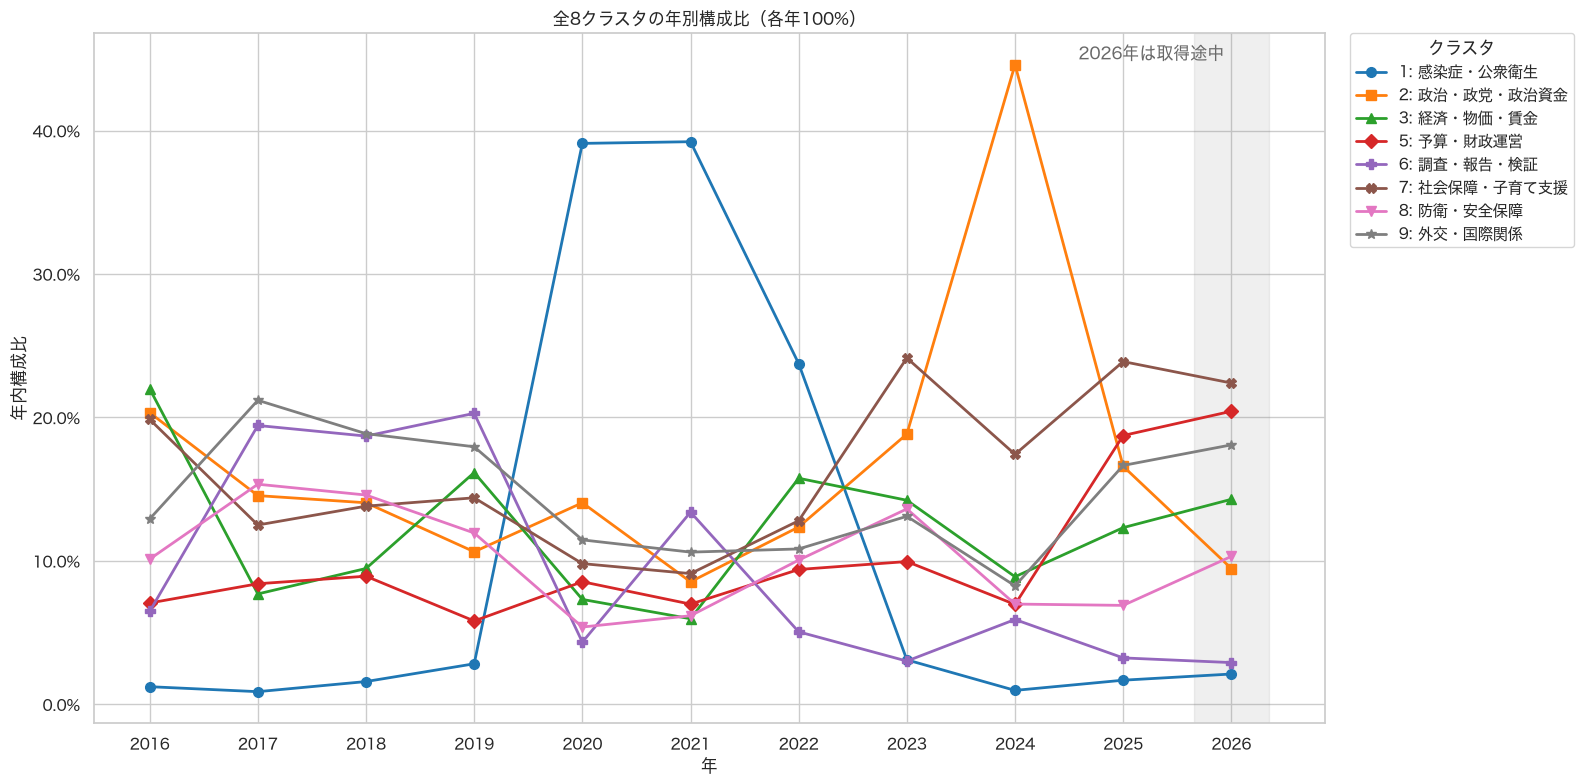

In [5]:
fig, ax = plt.subplots(figsize=(16, 8))
for cluster_id in CLUSTERS:
    values = yearly_long.loc[yearly_long['cluster'].eq(cluster_id)]
    ax.plot(
        values['year'], values['ratio_within_year'],
        label=f"{cluster_id}: {CLUSTER_LABELS[cluster_id]}",
        color=COLORS[cluster_id], marker=MARKERS[cluster_id],
        linewidth=2, markersize=7,
    )
ax.axvspan(2025.65, 2026.35, color='grey', alpha=.12)
ax.annotate('2026年は取得途中', xy=(2026, ax.get_ylim()[1]), xytext=(-5, -8), textcoords='offset points', ha='right', va='top', color='dimgray')
ax.set(title='全8クラスタの年別構成比（各年100%）', xlabel='年', ylabel='年内構成比', xticks=YEARS)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend(title='クラスタ', bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.tight_layout();

## 5. CSV出力と最終検証

In [6]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
yearly_counts.to_csv(OUTPUT_DIR / 'yearly_cluster_counts.csv', encoding='utf-8-sig')
yearly_ratios.to_csv(OUTPUT_DIR / 'yearly_cluster_ratios.csv', encoding='utf-8-sig')
yearly_long.to_csv(OUTPUT_DIR / 'yearly_cluster_long.csv', index=False, encoding='utf-8-sig')
saved_counts = pd.read_csv(OUTPUT_DIR / 'yearly_cluster_counts.csv', encoding='utf-8-sig', index_col='year')
saved_ratios = pd.read_csv(OUTPUT_DIR / 'yearly_cluster_ratios.csv', encoding='utf-8-sig', index_col='year')
saved_long = pd.read_csv(OUTPUT_DIR / 'yearly_cluster_long.csv', encoding='utf-8-sig')
assert int(saved_counts.to_numpy().sum()) == EXPECTED_ROWS
assert saved_ratios.sum(axis=1).sub(1.0).abs().max() < 1e-9
assert len(saved_long) == 88
assert not saved_long.duplicated(['year', 'cluster']).any()
assert saved_long['cluster_label'].notna().all()
print(f'出力先: {OUTPUT_DIR}')
print(f'検証完了: {len(df):,}発言、{len(YEARS)}年、{len(CLUSTERS)}クラスタ、long形式{len(saved_long)}行')

出力先: /Users/tasskkiu2/kokkai/analysis/all_clusters_yearly
検証完了: 36,142発言、11年、8クラスタ、long形式88行
